<div data-bmll-brand="notebook-header" style="display:flex;justify-content:space-between;align-items:center;padding:0 0 12px;border-bottom:2px solid #146BC1;margin-bottom:18px;font-family:Exo,Inter,Helvetica,Arial,sans-serif;">
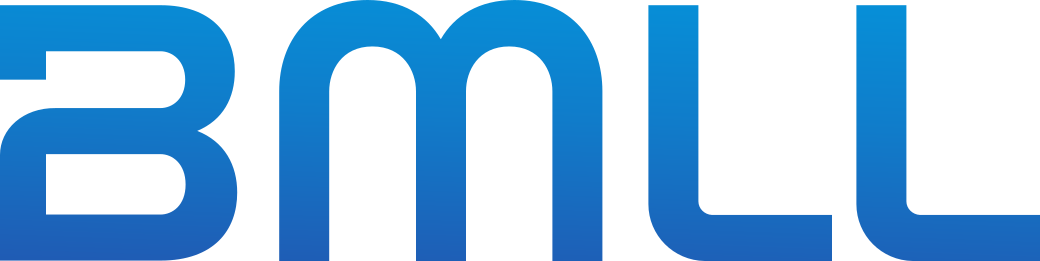
<span style="color:#878786;font-size:11px;"></span>
</div>


# VPIN: Volume-Synchronized Probability of Informed Trading

Scoped VPIN study using bmll.data.query: one ticker, two weeks of classified trades.

**Environment:** BMLL Query API (one ticker, two weeks)

In [2]:
# BMLL notebook style helpers. Generated from inputs/bmll-notebook-branding.
BMLL_COLOURS = {
    'primary': {'blue_1': '#333396', 'blue_2': '#146BC1', 'blue_3': '#009DDF'},
    'secondary': {
        'mauve': '#787BA7', 'grape': '#753C78', 'mint': '#5BACA1',
        'vanilla': '#F0D36E', 'tangerine': '#DE5F46', 'diesel': '#2E6195',
    },
    'tints': {
        'k_100': '#000000', 'k_80': '#575656', 'k_60': '#878786',
        'k_40': '#B3B2B2', 'k_20': '#DADADA', 'k_10': '#ECECEC',
    },
}
BMLL_PRIMARY_BLUE = BMLL_COLOURS['primary']['blue_2']
BMLL_CYCLE = [
    '#146BC1', '#DE5F46', '#5BACA1', '#753C78', '#F0D36E',
    '#2E6195', '#787BA7', '#333396', '#009DDF',
]
BMLL_SEQ_BLUE = [[0.0, '#E6F4FA'], [0.5, '#009DDF'], [1.0, '#333396']]
BMLL_SEQ_TANGERINE = [[0.0, '#FFF1ED'], [0.5, '#DE5F46'], [1.0, '#7C2614']]
BMLL_DIVERGING = [[0.0, '#DE5F46'], [0.5, '#F2F2F2'], [1.0, '#5BACA1']]

def add_bmll_source(fig):
    if not hasattr(fig, 'add_annotation'):
        return fig
    existing = getattr(fig.layout, 'annotations', None) or ()
    if any(getattr(a, 'name', None) == '_bmll_source' for a in existing):
        return fig
    fig.add_annotation(
        name='_bmll_source', xref='paper', yref='paper', x=1.0, y=0.0,
        xanchor='right', yanchor='top', yshift=-60, showarrow=False,
        text='Source: BMLL',
        font=dict(color=BMLL_PRIMARY_BLUE, size=11, family='Inter, Helvetica, Arial, sans-serif'),
    )
    return fig

def apply_bmll_plotly_style(fig, *, show_source=True):
    if hasattr(fig, 'update_layout'):
        fig.update_layout(
            font=dict(family='Inter, Helvetica, Arial, sans-serif', color='#1a1a1a'),
            colorway=BMLL_CYCLE,
            paper_bgcolor='white',
            plot_bgcolor='white',
            margin=dict(l=80, r=40, t=80, b=90),
        )
        fig.update_xaxes(showgrid=True, gridcolor='#ECECEC', zerolinecolor='#DADADA')
        fig.update_yaxes(showgrid=True, gridcolor='#ECECEC', zerolinecolor='#DADADA')
    if show_source:
        add_bmll_source(fig)
    return fig

try:
    import plotly.io as _pio
    _pio.templates['bmll'] = _pio.templates['plotly_white']
    _pio.templates['bmll'].layout.font = dict(family='Inter, Helvetica, Arial, sans-serif', color='#1a1a1a')
    _pio.templates['bmll'].layout.colorway = BMLL_CYCLE
    _pio.templates.default = 'bmll'
except Exception:
    pass

<div data-bmll-brand="section-header" style="display:flex;align-items:center;gap:10px;border-bottom:1px solid #DADADA;padding:6px 0 8px;margin:4px 0 10px;font-family:Exo,Inter,Helvetica,Arial,sans-serif;">
<span style="background:#146BC1;color:white;font-size:11px;font-weight:700;padding:2px 8px;border-radius:2px;letter-spacing:0.05em;">SECTION 1</span>
<span style="font-size:15px;font-weight:600;color:#1a1a1a;">BMLL Notebook Educational Series</span>
</div>
### VPIN Analysis: Volume-Synchronized Probability of Informed Trading

**VPIN** was introduced by **Marcos López de Prado and David Easley** as an intraday proxy for the probability of informed trading.

### Core Concept

Instead of dividing data into **fixed time intervals** (e.g., 5-minute bars), VPIN:

1. Divides trading into **equal-volume buckets**
2. Estimates **buy vs sell imbalance** inside each bucket
3. Measures **persistent imbalance** across recent buckets

### Interpretation

$$\text{VPIN} = \frac{1}{n \cdot V} \sum_{i=1}^{n} |V_i^{buy} - V_i^{sell}|$$

Where:
- $n$ = rolling window of buckets
- $V$ = volume per bucket
- $V_i^{buy}$, $V_i^{sell}$ = buy/sell volume in bucket $i$

**High VPIN** (sustained order flow imbalance) → High probability of informed trading → **Market toxicity**

**Low VPIN** (balanced order flow) → Low informed trading → **Normal market conditions**

### Typical Thresholds

- **VPIN < 0.3**: Low toxicity, normal trading
- **0.3 ≤ VPIN < 0.5**: Moderate toxicity, elevated information asymmetry
- **VPIN ≥ 0.5**: High toxicity, significant informed trading
- **VPIN > 0.7**: Extreme toxicity, potential crisis/flash crash conditions

**Scope.** The original tutorial ran two months of NKE trades. To stay within the query budget (one minute and 5 GB per query, and a fraction of the memory in a notebook) this version analyses **BMLL Query API (one ticker, two weeks)** for one ticker over two weeks; widen `strt_date`/`end_date` to extend it. Only the trade fields the analysis needs are read.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Set plot style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (12, 6)


pd.options.display.max_columns = None
pd.options.display.max_rows = 105

### Constants

Only the fields the analysis uses are requested. `BestBid/AskPriceAtPrimary` give the primary-market midpoint used to classify trades with an unknown aggressor side; the session window and `BMLLTradeType` restrict the study to continuous trading.

In [6]:
TRADE_COLS = [
    "ExchangeTicker", "MIC", "TradeTimestamp", "AggressorSide",
    "BestBidPriceAtPrimary", "BestAskPriceAtPrimary",
    "PostTradeMidAtPrimary", "BMLLTradeType", "Price", "Size",
]
# Continuous session, in exchange local time, and the trade types that are not continuous trading.
SESSION_TZ, SESSION_OPEN_MIN, SESSION_CLOSE_MIN = "America/New_York", 9 * 60 + 30, 16 * 60
NON_CONTINUOUS_TYPES = ["OTC", "UNCROSSING", "CLOSING_PRICE", "BENCHMARK_PRICE"]

### Helper functions

`infer_side_vectorized` labels trades whose aggressor side is unknown (Lee-Ready style: above/below the primary midpoint, tick rule at the midpoint). `compute_vpin` builds equal-volume buckets, measures the buy/sell imbalance in each and averages it over a rolling window.

In [8]:
def infer_side_vectorized(trades_df):
    """
    Vectorized inference of aggressor side for unknown trades.
    
    Parameters:
        trades_df: DataFrame with columns 'AggressorSide', 'InstrumentCurrencyPrice', 
                   'PreTradeMidAtPrimary', 'PostTradeMidAtPrimary'
    
    Returns:
        pd.Series: Inferred aggressor sides
    """
    # Start with existing aggressor sides
    aggressor = trades_df['AggressorSide'].copy()
    
    # Identify unknown trades
    unknown_mask = (aggressor == 0)
    
    # For unknown trades, calculate price relative to midpoint
    price_diff = trades_df['Price'] - trades_df['PreTradeMidAtPrimary']
    
    # Classify based on price relative to midpoint
    aggressor.loc[unknown_mask & (price_diff > 0)] = 1  # Above midpoint → Buy
    aggressor.loc[unknown_mask & (price_diff < 0)] = 2  # Below midpoint → Sell
    
    # For trades exactly at midpoint, use tick rule (next midpoint)
    at_midpoint_mask = unknown_mask & (price_diff == 0)
    midpoint_change = trades_df['PostTradeMidAtPrimary'] - trades_df['PreTradeMidAtPrimary']
    
    aggressor.loc[at_midpoint_mask & (midpoint_change >= 0)] = 1  # Uptick/no change → Buy
    aggressor.loc[at_midpoint_mask & (midpoint_change < 0)] = 2   # Downtick → Sell
    
    return aggressor

In [9]:
def compute_vpin(
    trades, 
    bucket_volume, 
    window, 
    timestamp_col,
    drop_incomplete_bucket=True
):
    """
    Compute VPIN using volume buckets and aggressor-side trade classification.

    Parameters:
        trades: pd.DataFrame
            Must contain 'Price', 'Size', and 'AggressorSide'
            (1 = buy, 2 = sell), plus a timestamp column.
        bucket_volume: int
            Fixed traded volume per bucket (volume time).
        window: int
            Rolling number of buckets used for VPIN.
        timestamp_col: str
            Column used to sort trades chronologically.
        drop_incomplete_bucket: bool
            If True, drop the last bucket if it's incomplete.

    Returns:
        pd.DataFrame
            Bucket-level data with buy/sell volume, imbalance,
            VPIN, bucket returns, timestamps, and forward 30-bucket volatility.
    """
    # Validation
    if trades.empty:
        raise ValueError("Empty trades DataFrame")
    
    required_cols = ['Price', 'Size', 'AggressorSide', timestamp_col]
    missing_cols = [col for col in required_cols if col not in trades.columns]
    if missing_cols:
        raise ValueError(f"Missing required columns: {missing_cols}")
    
    # Check for unknown aggressor sides
    unknown_count = (trades['AggressorSide'] == 0).sum()
    if unknown_count > 0:
        warnings.warn(f"{unknown_count} trades still have unknown aggressor side and will be excluded")
    
    trades = trades.sort_values(timestamp_col).copy()

    # Classify trades by aggressor side
    trades['buy_volume'] = np.where(trades['AggressorSide'] == 1, trades['Size'], 0)
    trades['sell_volume'] = np.where(trades['AggressorSide'] == 2, trades['Size'], 0)

    # Create cumulative volume
    trades['cum_volume'] = trades['Size'].cumsum()

    # Assign bucket IDs
    trades['bucket'] = (trades['cum_volume'] // bucket_volume).astype(int)
    
    # Track original known sides count for diagnostics
    total_buy_vol = trades['buy_volume'].sum()
    total_sell_vol = trades['sell_volume'].sum()
    total_vol = trades['Size'].sum()
    classified_vol = total_buy_vol + total_sell_vol
    
    print(f"Volume Classification:")
    print(f"  Total volume: {total_vol:,.0f}")
    print(f"  Classified volume: {classified_vol:,.0f} ({classified_vol/total_vol*100:.1f}%)")
    print(f"  Buy volume: {total_buy_vol:,.0f} ({total_buy_vol/classified_vol*100:.1f}% of classified)")
    print(f"  Sell volume: {total_sell_vol:,.0f} ({total_sell_vol/classified_vol*100:.1f}% of classified)")
    print(f"  Unclassified volume: {total_vol - classified_vol:,.0f}")

    # Aggregate per bucket
    bucketed = trades.groupby('bucket').agg({
        'buy_volume': 'sum',
        'sell_volume': 'sum',
        'Size': 'sum',  # Total volume in bucket
        timestamp_col: ['first', 'last'],
        'Price': ['first', 'last']
    })
    
    # Flatten multi-level columns
    bucketed.columns = ['_'.join(col).strip() if col[1] else col[0] for col in bucketed.columns.values]
    bucketed.columns = ['buy_volume', 'sell_volume', 'total_volume', 
                        'timestamp_start', 'timestamp_end', 'price_start', 'price_last']
    
    # Calculate midpoint timestamp for plotting
    bucketed['timestamp'] = bucketed['timestamp_start'] + \
        (bucketed['timestamp_end'] - bucketed['timestamp_start']) / 2
    
    # Duration of each bucket
    bucketed['duration_seconds'] = (bucketed['timestamp_end'] - bucketed['timestamp_start']).dt.total_seconds()

    # Drop incomplete last bucket if requested
    if drop_incomplete_bucket:
        complete_buckets = bucketed[bucketed['total_volume'] >= bucket_volume * 0.95]  # 95% threshold
        n_dropped = len(bucketed) - len(complete_buckets)
        if n_dropped > 0:
            print(f"\nDropped {n_dropped} incomplete bucket(s)")
        bucketed = complete_buckets
    
    # Flag complete vs incomplete buckets
    bucketed['is_complete'] = bucketed['total_volume'] >= bucket_volume * 0.95
    
    # Calculate imbalance
    bucketed['imbalance'] = np.abs(
        bucketed['buy_volume'] - bucketed['sell_volume']
    )
    
    # Calculate signed imbalance (for visualization)
    bucketed['signed_imbalance'] = bucketed['buy_volume'] - bucketed['sell_volume']

    # Compute rolling VPIN
    bucketed['vpin'] = (
        bucketed['imbalance']
        .rolling(window, min_periods=window)
        .sum() / (window * bucket_volume)
    )
    
    # Check if we have enough data
    valid_vpin_count = bucketed['vpin'].notna().sum()
    if valid_vpin_count < window:
        warnings.warn(f"Only {valid_vpin_count} valid VPIN values. Need at least {window} buckets.")
    
    print(f"\nBucket Statistics:")
    print(f"  Total buckets: {len(bucketed)}")
    print(f"  Valid VPIN observations: {valid_vpin_count}")
    print(f"  Target volume per bucket: {bucket_volume:,.0f}")
    print(f"  Actual avg volume per bucket: {bucketed['total_volume'].mean():,.0f}")

    # Calculate bucket returns
    bucketed['returns'] = bucketed['price_last'].pct_change()
    
    # Forward-looking realized volatility (for ex-post analysis only)
    bucketed['realized_vol_next_30'] = (
        bucketed['returns'].rolling(30, min_periods=20).std().shift(-30)
    )

    return bucketed

<div data-bmll-brand="section-header" style="display:flex;align-items:center;gap:10px;border-bottom:1px solid #DADADA;padding:6px 0 8px;margin:4px 0 10px;font-family:Exo,Inter,Helvetica,Arial,sans-serif;">
<span style="background:#146BC1;color:white;font-size:11px;font-weight:700;padding:2px 8px;border-radius:2px;letter-spacing:0.05em;">SECTION 2</span>
<span style="font-size:15px;font-weight:600;color:#1a1a1a;">Load trades</span>
</div>

In [11]:
ticker = "NKE"          # US ticker
mic = "@SIP"            # US consolidated market
strt_date = "2025-04-01"
end_date = "2025-04-14"

In [12]:
import bmll.data

# One call for the whole range (never one per day). `MIC="@SIP"` is the US consolidated feed.
trades = bmll.data.query(
    "trades_plus",
    start_date=strt_date,
    end_date=end_date,
    MIC=mic,
    ExchangeTicker=ticker,
    columns=TRADE_COLS,
)
print(f"{len(trades):,} trades loaded")

3,612,266 trades loaded


### Classify and filter

Trades with an unknown aggressor side are labelled from the primary midpoint. The study then keeps **continuous trading**: trades between 09:30 and 16:00 New York time that are not OTC, uncrossing, closing-price or benchmark prints.

The session is selected by the clock rather than by `MarketStateAtPrimary`. For this ticker and period that field stays on `OPENING_AUCTION` for entire sessions (for example 2025-04-01, 04-07, 04-08 and 04-14), so filtering on it would silently drop those days and leave VPIN undefined across them.

In [14]:
# where no aggressor side is reported, infer it from the primary-market midpoint
trades['PreTradeMidAtPrimary'] = 0.5 * (trades['BestBidPriceAtPrimary'] + trades['BestAskPriceAtPrimary'])
trades['AggressorSide'] = infer_side_vectorized(trades)

# continuous session in exchange local time (timestamps are UTC), excluding non-continuous trade types
_local = pd.to_datetime(trades['TradeTimestamp'], utc=True).dt.tz_convert(SESSION_TZ)
_minute = _local.dt.hour * 60 + _local.dt.minute
in_session = (_minute >= SESSION_OPEN_MIN) & (_minute < SESSION_CLOSE_MIN)
trades_cont = trades[in_session & ~trades['BMLLTradeType'].isin(NON_CONTINUOUS_TYPES)].copy()

sessions = _local[trades_cont.index].dt.date.nunique()
print(f"{len(trades_cont):,} continuous-session trades over {sessions} sessions ({len(trades_cont) / max(len(trades), 1):.0%} of loaded)")

2,149,658 continuous-session trades over 10 sessions (60% of loaded)


In [15]:
# Set VPIN parameters
# Typical values from literature:
# - bucket_volume: ~1/50 of daily volume (Easley et al.)
# - window: 50 buckets (standard)

daily_volume = trades_cont['Size'].sum() / sessions  # actual sessions, robust to holidays
bucket_volume = int(daily_volume / 50)  # 50 buckets per day
window = 50

print(f"VPIN Parameters:")
print(f"  Daily volume: {daily_volume:,.0f}")
print(f"  Bucket volume: {bucket_volume:,.0f}")
print(f"  Rolling window: {window} buckets")
print(f"  Expected buckets: ~{int(daily_volume / bucket_volume)}")
print("\n" + "="*60)

# Compute VPIN
bucketed = compute_vpin(
    trades=trades_cont,
    bucket_volume=bucket_volume,
    window=window,
    timestamp_col='TradeTimestamp',  # Adjust to your column name
    drop_incomplete_bucket=True
)

print("\n" + "="*60)
print("VPIN COMPUTATION COMPLETE")
print("="*60)

VPIN Parameters:
  Daily volume: 18,486,865
  Bucket volume: 369,737
  Rolling window: 50 buckets
  Expected buckets: ~50

Volume Classification:
  Total volume: 184,868,648
  Classified volume: 184,868,648 (100.0%)
  Buy volume: 98,046,341 (53.0% of classified)
  Sell volume: 86,822,307 (47.0% of classified)
  Unclassified volume: 0

Dropped 18 incomplete bucket(s)

Bucket Statistics:
  Total buckets: 480
  Valid VPIN observations: 431
  Target volume per bucket: 369,737
  Actual avg volume per bucket: 378,340

VPIN COMPUTATION COMPLETE


<div data-bmll-brand="section-header" style="display:flex;align-items:center;gap:10px;border-bottom:1px solid #DADADA;padding:6px 0 8px;margin:4px 0 10px;font-family:Exo,Inter,Helvetica,Arial,sans-serif;">
<span style="background:#146BC1;color:white;font-size:11px;font-weight:700;padding:2px 8px;border-radius:2px;letter-spacing:0.05em;">SECTION 3</span>
<span style="font-size:15px;font-weight:600;color:#1a1a1a;">Summary Statistics</span>
</div>

In [17]:
# Summary statistics
vpin_stats = bucketed['vpin'].dropna().describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])

print("\nVPIN Summary Statistics:")
print(vpin_stats)

# Toxicity levels
vpin_valid = bucketed['vpin'].dropna()
low_toxicity = (vpin_valid < 0.3).sum()
moderate_toxicity = ((vpin_valid >= 0.3) & (vpin_valid < 0.5)).sum()
high_toxicity = ((vpin_valid >= 0.5) & (vpin_valid < 0.7)).sum()
extreme_toxicity = (vpin_valid >= 0.7).sum()

print(f"\nToxicity Distribution:")
print(f"  Low (VPIN < 0.3): {low_toxicity} ({low_toxicity/len(vpin_valid)*100:.1f}%)")
print(f"  Moderate (0.3 ≤ VPIN < 0.5): {moderate_toxicity} ({moderate_toxicity/len(vpin_valid)*100:.1f}%)")
print(f"  High (0.5 ≤ VPIN < 0.7): {high_toxicity} ({high_toxicity/len(vpin_valid)*100:.1f}%)")
print(f"  Extreme (VPIN ≥ 0.7): {extreme_toxicity} ({extreme_toxicity/len(vpin_valid)*100:.1f}%)")


VPIN Summary Statistics:
count    431.000000
mean       0.146614
std        0.032692
min        0.078340
5%         0.109990
25%        0.124032
50%        0.137717
75%        0.166186
95%        0.221218
max        0.238473
Name: vpin, dtype: float64

Toxicity Distribution:
  Low (VPIN < 0.3): 431 (100.0%)
  Moderate (0.3 ≤ VPIN < 0.5): 0 (0.0%)
  High (0.5 ≤ VPIN < 0.7): 0 (0.0%)
  Extreme (VPIN ≥ 0.7): 0 (0.0%)


### Plot 1: VPIN Time Series with Toxicity Threshold Bands


VPIN Range: [0.078, 0.238]
Mean VPIN: 0.147
Median VPIN: 0.138


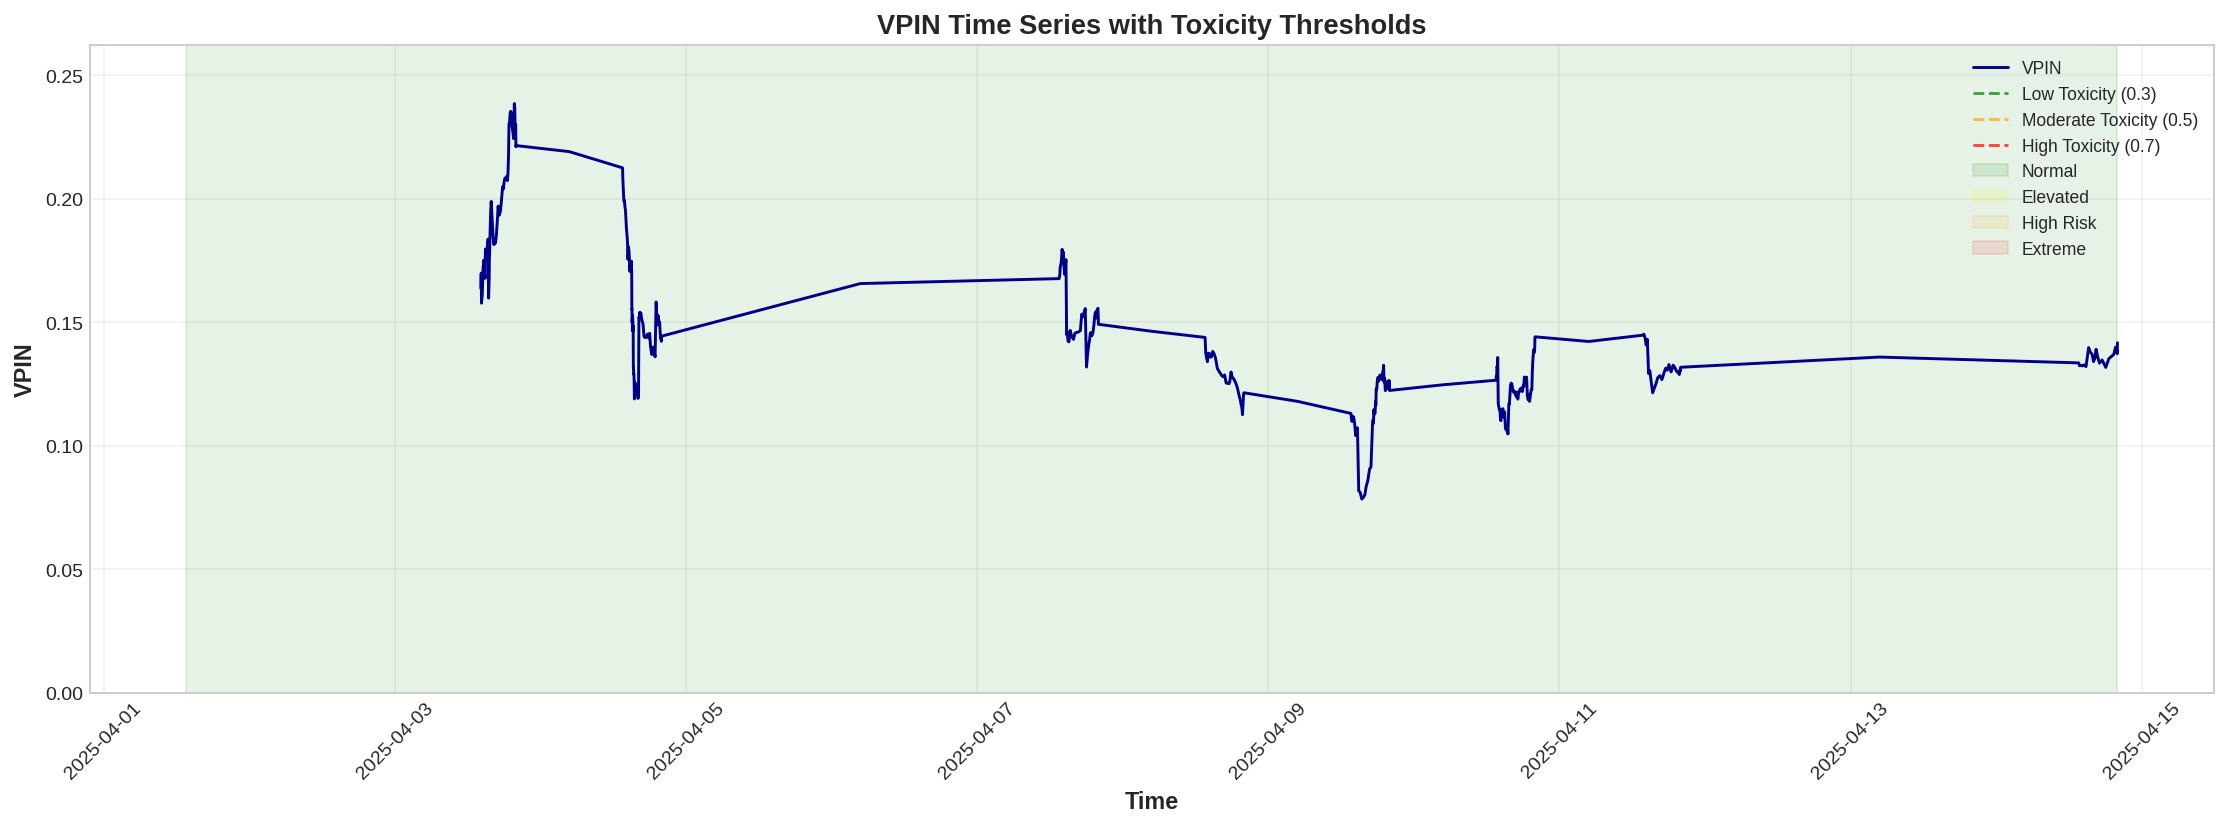

In [19]:
fig, ax = plt.subplots(figsize=(16, 6))

# Plot VPIN time series
ax.plot(bucketed['timestamp'], bucketed['vpin'], linewidth=1.5, color='darkblue', label='VPIN')

# Add toxicity threshold bands
ax.axhline(0.3, color='green', linestyle='--', linewidth=1.5, alpha=0.7, label='Low Toxicity (0.3)')
ax.axhline(0.5, color='orange', linestyle='--', linewidth=1.5, alpha=0.7, label='Moderate Toxicity (0.5)')
ax.axhline(0.7, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='High Toxicity (0.7)')

# Fill regions
ax.fill_between(bucketed['timestamp'], 0, 0.3, alpha=0.1, color='green', label='Normal')
ax.fill_between(bucketed['timestamp'], 0.3, 0.5, alpha=0.1, color='yellow', label='Elevated')
ax.fill_between(bucketed['timestamp'], 0.5, 0.7, alpha=0.1, color='orange', label='High Risk')
ax.fill_between(bucketed['timestamp'], 0.7, 1, alpha=0.1, color='red', label='Extreme')

ax.set_xlabel('Time', fontsize=12, fontweight='bold')
ax.set_ylabel('VPIN', fontsize=12, fontweight='bold')
ax.set_title('VPIN Time Series with Toxicity Thresholds', fontsize=14, fontweight='bold')
ax.legend(loc='upper right', fontsize=9)
ax.grid(True, alpha=0.3)
ax.set_ylim(0, min(1.0, bucketed['vpin'].max() * 1.1))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(f"\nVPIN Range: [{bucketed['vpin'].min():.3f}, {bucketed['vpin'].max():.3f}]")
print(f"Mean VPIN: {bucketed['vpin'].mean():.3f}")
print(f"Median VPIN: {bucketed['vpin'].median():.3f}")

### Plot 2: VPIN Distribution with Normal Overlay


Normality Test (Shapiro-Wilk):
  p-value: 0.0000
  ⚠ VPIN distribution deviates from normality (p < 0.05)


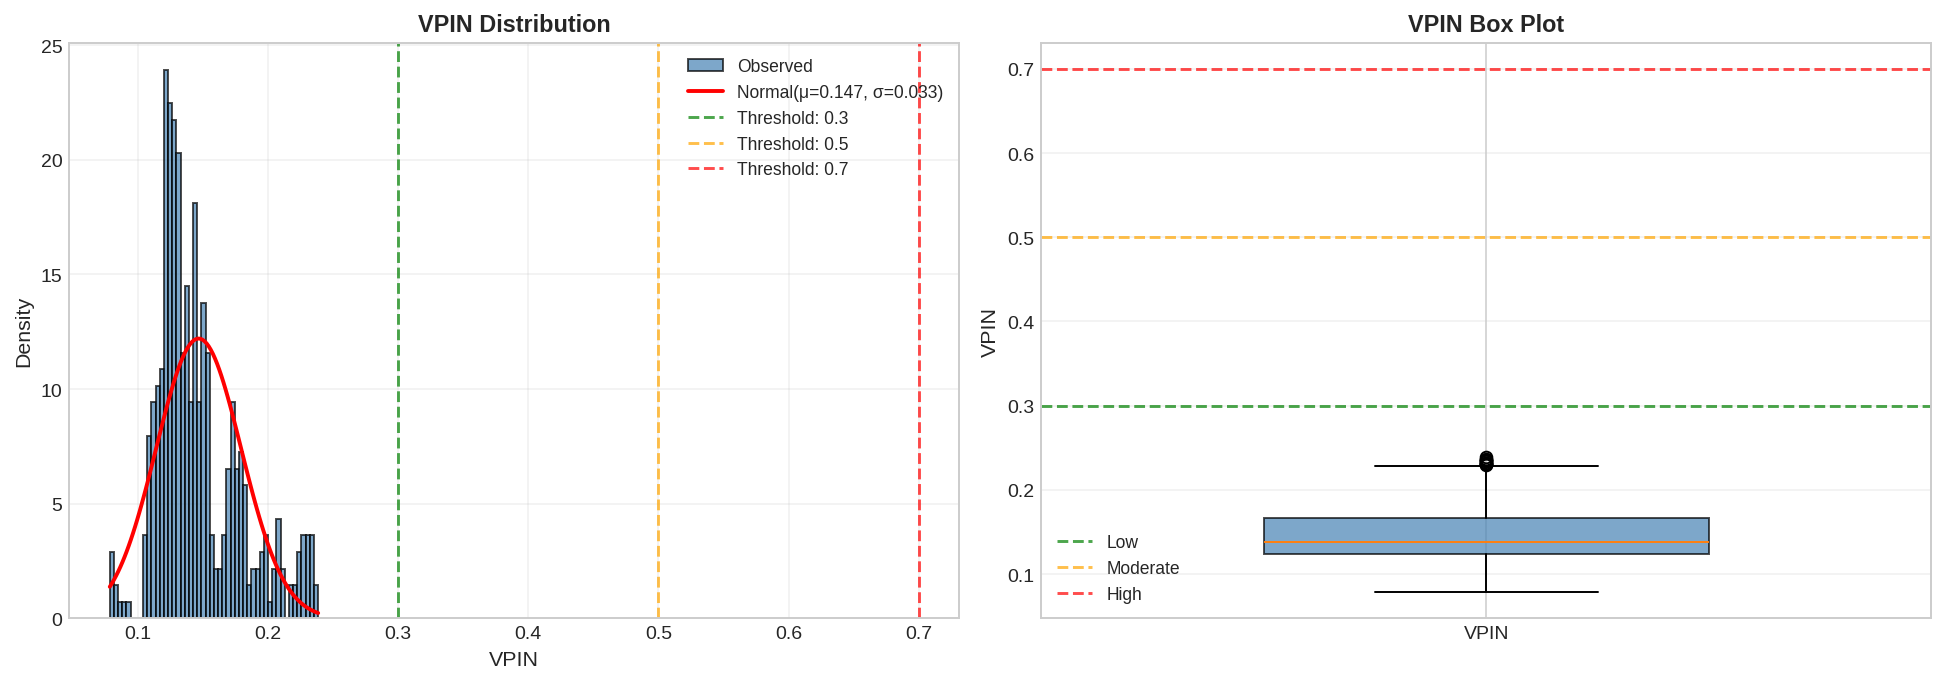

In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: Histogram with normal overlay
vpin_data = bucketed['vpin'].dropna()
ax1.hist(vpin_data, bins=50, density=True, alpha=0.7, color='steelblue', edgecolor='black', label='Observed')

# Fit normal distribution
mu, sigma = vpin_data.mean(), vpin_data.std()
x = np.linspace(vpin_data.min(), vpin_data.max(), 100)
ax1.plot(x, stats.norm.pdf(x, mu, sigma), 'r-', linewidth=2, label=f'Normal(μ={mu:.3f}, σ={sigma:.3f})')

# Add threshold lines
ax1.axvline(0.3, color='green', linestyle='--', linewidth=1.5, alpha=0.7, label='Threshold: 0.3')
ax1.axvline(0.5, color='orange', linestyle='--', linewidth=1.5, alpha=0.7, label='Threshold: 0.5')
ax1.axvline(0.7, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='Threshold: 0.7')

ax1.set_xlabel('VPIN', fontsize=11)
ax1.set_ylabel('Density', fontsize=11)
ax1.set_title('VPIN Distribution', fontsize=12, fontweight='bold')
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)

# Right: Box plot with percentiles
bp = ax2.boxplot([vpin_data], vert=True, patch_artist=True, widths=0.5)
bp['boxes'][0].set_facecolor('steelblue')
bp['boxes'][0].set_alpha(0.7)

# Add threshold lines
ax2.axhline(0.3, color='green', linestyle='--', linewidth=1.5, alpha=0.7, label='Low')
ax2.axhline(0.5, color='orange', linestyle='--', linewidth=1.5, alpha=0.7, label='Moderate')
ax2.axhline(0.7, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='High')

ax2.set_ylabel('VPIN', fontsize=11)
ax2.set_title('VPIN Box Plot', fontsize=12, fontweight='bold')
ax2.set_xticklabels(['VPIN'])
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# Normality test
_, p_value = stats.shapiro(vpin_data[:5000])  # Shapiro-Wilk test
print(f"\nNormality Test (Shapiro-Wilk):")
print(f"  p-value: {p_value:.4f}")
if p_value > 0.05:
    print(f"  ✓ VPIN distribution is approximately normal (p > 0.05)")
else:
    print(f"  ⚠ VPIN distribution deviates from normality (p < 0.05)")

### Plot 3: VPIN vs Realized Volatility (Scatter)


VPIN vs Realized Volatility:
  Pearson correlation: 0.1725
  Spearman correlation: 0.2108
  Sample size: 401 buckets
  ⚠ Weak positive relationship detected


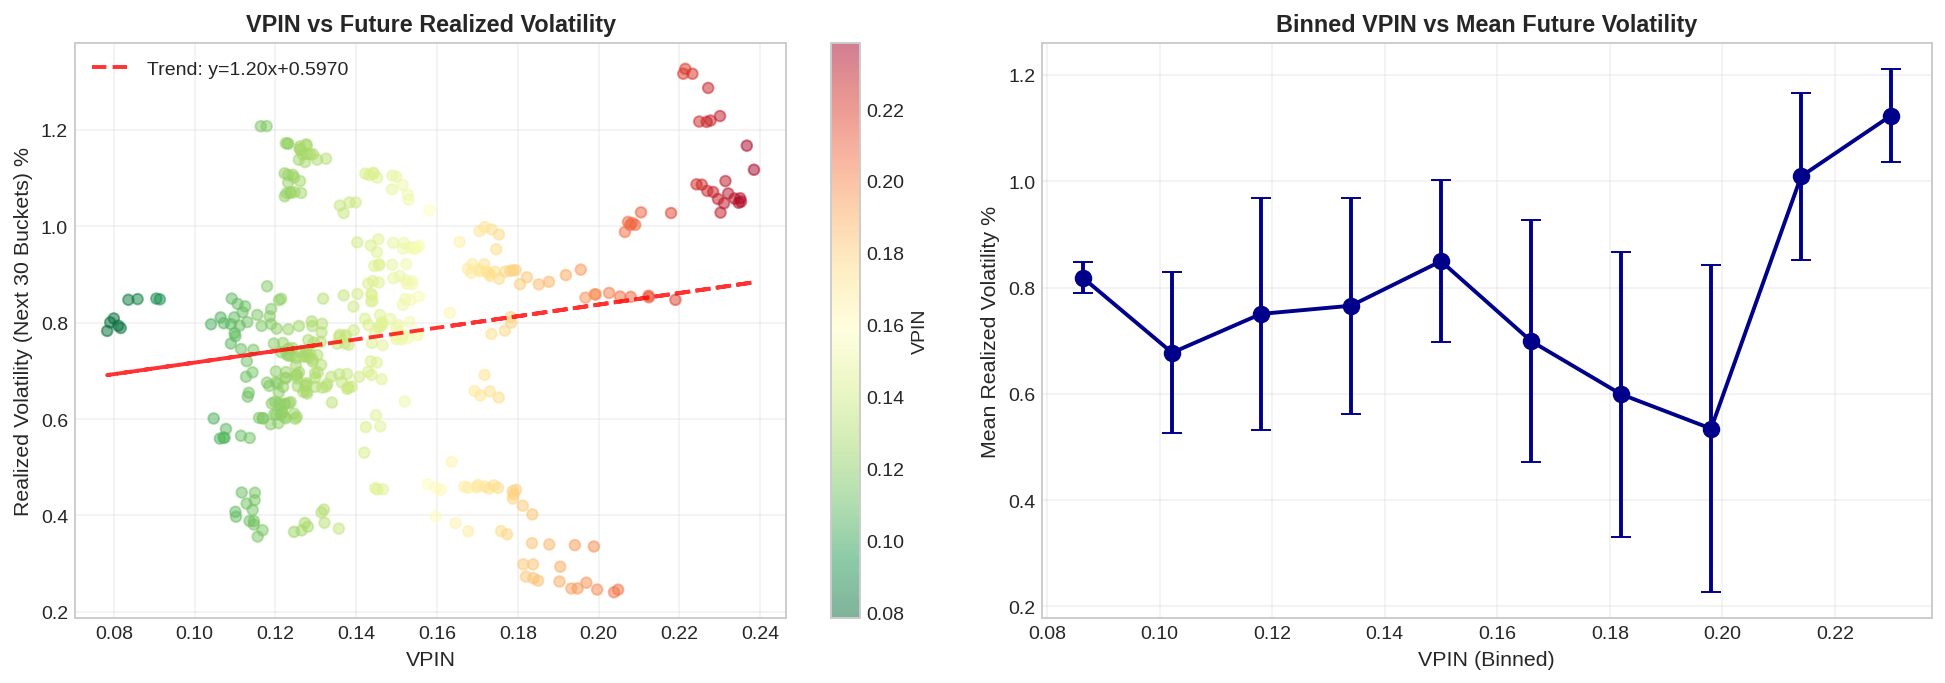

In [23]:
# Filter data with both VPIN and realized vol
plot_data = bucketed[['vpin', 'realized_vol_next_30']].dropna()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: Scatter plot
scatter = ax1.scatter(plot_data['vpin'], plot_data['realized_vol_next_30']*100, 
                     alpha=0.5, s=30, c=plot_data['vpin'], cmap='RdYlGn_r')
ax1.set_xlabel('VPIN', fontsize=11)
ax1.set_ylabel('Realized Volatility (Next 30 Buckets) %', fontsize=11)
ax1.set_title('VPIN vs Future Realized Volatility', fontsize=12, fontweight='bold')
ax1.grid(True, alpha=0.3)
plt.colorbar(scatter, ax=ax1, label='VPIN')

# Add trend line
z = np.polyfit(plot_data['vpin'], plot_data['realized_vol_next_30']*100, 1)
p = np.poly1d(z)
ax1.plot(plot_data['vpin'], p(plot_data['vpin']), "r--", linewidth=2, alpha=0.8, label=f'Trend: y={z[0]:.2f}x+{z[1]:.4f}')
ax1.legend()

# Right: Binned analysis
plot_data_binned = plot_data.copy()
plot_data_binned['vpin_bin'] = pd.cut(plot_data_binned['vpin'], bins=10)
binned_stats = plot_data_binned.groupby('vpin_bin')['realized_vol_next_30'].agg(['mean', 'std', 'count'])

# Get bin centers for plotting
bin_centers = [interval.mid for interval in binned_stats.index]
ax2.errorbar(bin_centers, binned_stats['mean']*100, yerr=binned_stats['std']*100, 
             fmt='o-', linewidth=2, markersize=8, capsize=5, color='darkblue')
ax2.set_xlabel('VPIN (Binned)', fontsize=11)
ax2.set_ylabel('Mean Realized Volatility %', fontsize=11)
ax2.set_title('Binned VPIN vs Mean Future Volatility', fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Correlation analysis
corr_pearson = plot_data['vpin'].corr(plot_data['realized_vol_next_30'])
corr_spearman = plot_data['vpin'].corr(plot_data['realized_vol_next_30'], method='spearman')

print(f"\nVPIN vs Realized Volatility:")
print(f"  Pearson correlation: {corr_pearson:.4f}")
print(f"  Spearman correlation: {corr_spearman:.4f}")
print(f"  Sample size: {len(plot_data)} buckets")

if corr_pearson > 0.3:
    print(f"  ✓ Moderate-to-strong positive relationship detected")
elif corr_pearson > 0.1:
    print(f"  ⚠ Weak positive relationship detected")
else:
    print(f"  ⚠ Little to no relationship detected")

### Plot 4: VPIN Regime Analysis (High vs Low)


Regime Comparison (T-Test):
  Low VPIN mean return: -0.0304%
  High VPIN mean return: -0.0137%
  T-statistic: -0.1855
  P-value: 0.8529
  ⚠ No statistically significant difference in returns (p >= 0.05)


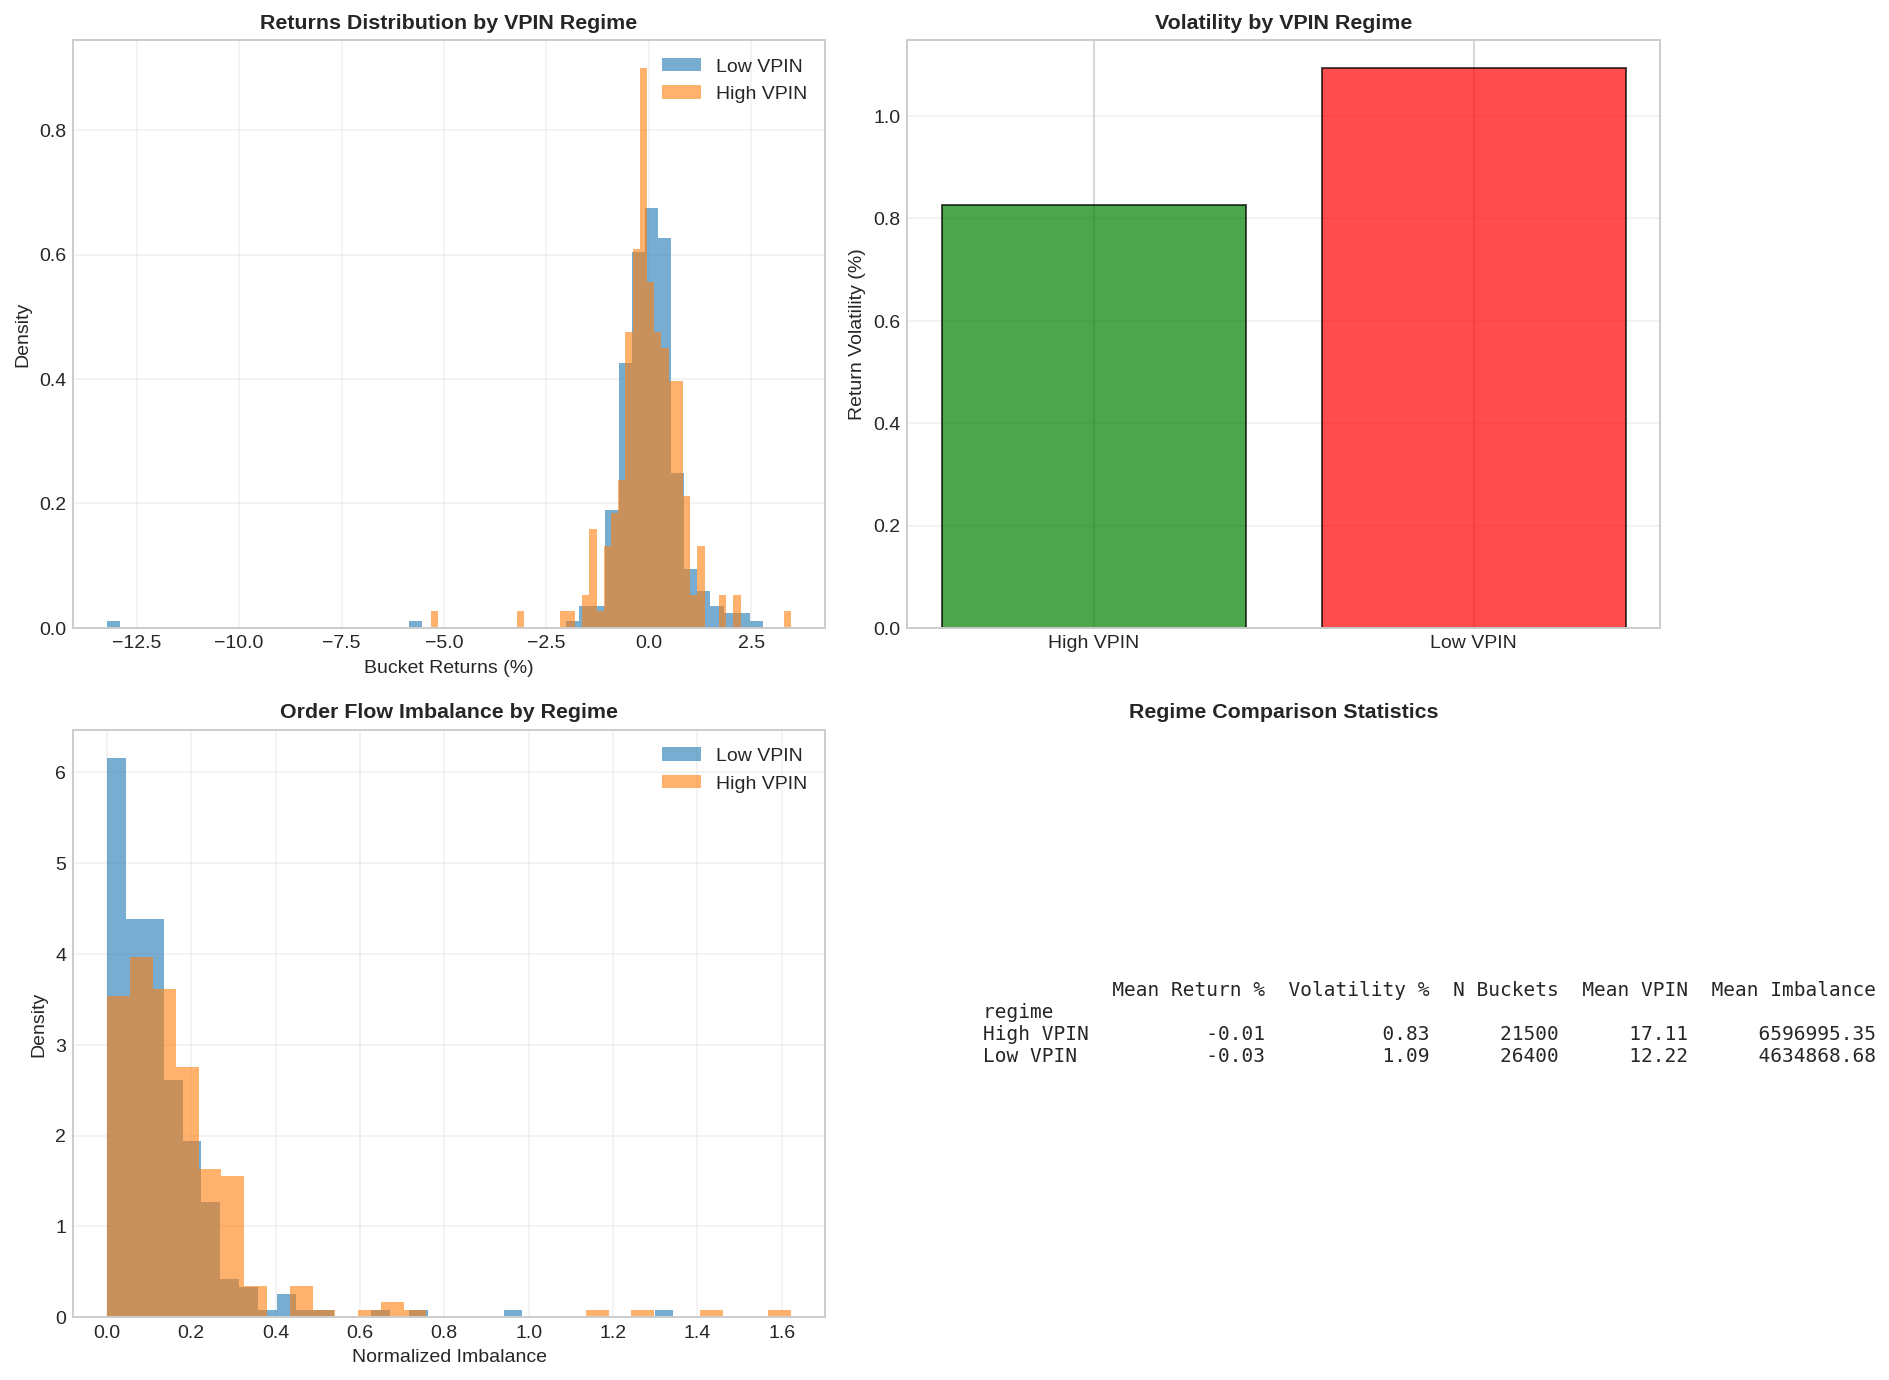

In [25]:
# Define regimes
vpin_median = bucketed['vpin'].median()
bucketed_regime = bucketed.copy()
bucketed_regime['regime'] = 'Low VPIN'
bucketed_regime.loc[bucketed_regime['vpin'] > vpin_median, 'regime'] = 'High VPIN'

# Alternative: use threshold-based regimes
bucketed_regime['regime_threshold'] = 'Normal'
bucketed_regime.loc[bucketed_regime['vpin'] >= 0.3, 'regime_threshold'] = 'Elevated'
bucketed_regime.loc[bucketed_regime['vpin'] >= 0.5, 'regime_threshold'] = 'High Toxicity'

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Top-left: Returns distribution by regime
for regime in ['Low VPIN', 'High VPIN']:
    data = bucketed_regime[bucketed_regime['regime'] == regime]['returns'].dropna() * 100
    axes[0, 0].hist(data, bins=50, alpha=0.6, label=regime, density=True)
axes[0, 0].set_xlabel('Bucket Returns (%)', fontsize=10)
axes[0, 0].set_ylabel('Density', fontsize=10)
axes[0, 0].set_title('Returns Distribution by VPIN Regime', fontsize=11, fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Top-right: Volatility by regime
regime_stats = bucketed_regime.groupby('regime')['returns'].agg(
    lambda x: x.std() * 100
).reset_index()
regime_stats.columns = ['Regime', 'Volatility (%)']
axes[0, 1].bar(regime_stats['Regime'], regime_stats['Volatility (%)'], 
               color=['green', 'red'], alpha=0.7, edgecolor='black')
axes[0, 1].set_ylabel('Return Volatility (%)', fontsize=10)
axes[0, 1].set_title('Volatility by VPIN Regime', fontsize=11, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3, axis='y')

# Bottom-left: Imbalance by regime
for regime in ['Low VPIN', 'High VPIN']:
    data = bucketed_regime[bucketed_regime['regime'] == regime]['imbalance'] / bucket_volume
    axes[1, 0].hist(data, bins=30, alpha=0.6, label=regime, density=True)
axes[1, 0].set_xlabel('Normalized Imbalance', fontsize=10)
axes[1, 0].set_ylabel('Density', fontsize=10)
axes[1, 0].set_title('Order Flow Imbalance by Regime', fontsize=11, fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Bottom-right: Summary statistics table
axes[1, 1].axis('off')
summary_table = bucketed_regime.groupby('regime').agg({
    'returns': ['mean', 'std', 'count'],
    'vpin': 'mean',
    'imbalance': 'mean'
}).round(4) * 100  # Convert to percentages

summary_table.columns = ['Mean Return %', 'Volatility %', 'N Buckets', 'Mean VPIN', 'Mean Imbalance']
table_text = summary_table.to_string()
axes[1, 1].text(0.1, 0.5, table_text, fontsize=10, family='monospace', 
                verticalalignment='center', transform=axes[1, 1].transAxes)
axes[1, 1].set_title('Regime Comparison Statistics', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

# Statistical tests
low_vpin_returns = bucketed_regime[bucketed_regime['regime'] == 'Low VPIN']['returns'].dropna()
high_vpin_returns = bucketed_regime[bucketed_regime['regime'] == 'High VPIN']['returns'].dropna()
t_stat, p_value = stats.ttest_ind(low_vpin_returns, high_vpin_returns)

print(f"\nRegime Comparison (T-Test):")
print(f"  Low VPIN mean return: {low_vpin_returns.mean()*100:.4f}%")
print(f"  High VPIN mean return: {high_vpin_returns.mean()*100:.4f}%")
print(f"  T-statistic: {t_stat:.4f}")
print(f"  P-value: {p_value:.4f}")
if p_value < 0.05:
    print(f"  ✓ Statistically significant difference in returns (p < 0.05)")
else:
    print(f"  ⚠ No statistically significant difference in returns (p >= 0.05)")